<a href="https://colab.research.google.com/github/GerardoMunoz/IoT_ws/blob/main/09_Taller_Arm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# @title
# To Do
# Revisar que los tipos de objetos sean correctos en los constructores y demás argunetos
# En las operaciones de los Join devolver Join y añadir combinación lineal para ahorrar crear objetos intermedios, o crear vectores para esas operaciones


from IPython.display import SVG, display
import math
from math import cos, sin, tan, pi, sqrt, atan2, acos, asin
import ipywidgets as widgets


class Vec:
    def __init__(self, x, y):
        self.x = x
        self.y = y
        self.xy = (self.x, self.y)

    def __getitem__(self, key):
        return self.xy[key]

    def __add__(self, other):
        return Vec(self[0]+other[0], self[1]+other[1])

    def __radd__(self, other):
        return Vec(self[0]+other[0], self[1]+other[1])

    def __sub__(self, other):
        return Vec(self[0]-other[0], self[1]-other[1])

    def __rsub__(self, other):
        return Vec(-self[0]+other[0], -self[1]+other[1])

    def __mul__(self, other):
        return Vec(self[0]*other, self[1]*other)

    def __rmul__(self, other):
        return Vec(self[0]*other, self[1]*other)

    def __div__(self, other):
        return Vec(self[0]/other, self[1]/other)

    def rot(self,angle):
        x = self[0] * cos(angle) - self[1] * sin(angle)
        y = self[0] * sin(angle) + self[1] * cos(angle)
        return Vec(x,y)

    def rot_deg(self,angle):
        return self.rot(angle*pi/180)

    def angle_line(self,other):
        return atan2(other[1]-self[1],other[0]-self[0])

    def atan2(self):
        return atan2(self[1],self[0])

    def __str__(self):
        return f"({self[0]},{self[1]})"

    def norm(self):
        return sqrt(self[0]**2+self[1]**2)

    @staticmethod
    def combLin( *listVec):
        """
        list of tuples of (escalar, vector)
        """
        x,y=0,0
        for vec in listVec:
            if isinstance(vec, tuple):
                escalar=vec[0]
                vec=vec[1]
            x+=vec[0]
            y+=vec[1]
        return Vec(x,y)


class Join_graph:
    def __init__(self, canvas,xy, label="",radius=5, color="gray", color_text="gray",font_size="16",move_text=(-10,-4),visible=True):
        self.canvas = canvas
        canvas.add(self)
        self.xy = xy
        self.label = label
        self.radius = radius
        self.color_point = color
        self.color_text = color_text
        self.font_size = font_size
        self.move_text = move_text
        self.visible=visible

    def get_svg(self):
        x, y = self.canvas.transform(self.xy)

        svg = f'\n<circle cx="{x}" cy="{y}" r="{self.radius}" fill="{self.color_point}" />'

        if self.label:
            svg += f'\n<text x="{x + 5}" y="{y - 5}" fill="{self.color_text}" font-size="{self.font_size}">{self.label}</text>'

        return svg
    # def get_svg(self):
    #     svg=""
    #     if self.visible:
    #         svg += f'\n<circle cx="{self.xy[0]}" cy="{self.xy[1]}" r="{self.radius}" fill="{self.color_point}" />'
    #     if self.label:
    #         svg += f'\n<text x="{self.xy[0] + self.move_text[0]}" y="{self.xy[1] + self.move_text[1]}" fill="{self.color_text}" font-size="{self.font_size}">{self.label}</text>'
    #     return svg

    def x(self):
        return self.xy[0]

    def y(self):
        return self.xy[1]

    def __getitem__(self, key):
        return self.xy[key]




class Link_graph:
    def __init__(self,canvas, P0, P1, label="", thickness=3, color="gray", color_text="gray",font_size="16",move_text=(-20,-5)):
        self.canvas = canvas
        canvas.add(self)
        self.P0 = P0
        self.P1 = P1
        self.label = label
        self.thickness = thickness
        self.color_line = color
        self.color_text = color_text
        self.font_size = font_size
        self.move_text = move_text


    def length(self):
        dx = self.P1[0] - self.P0[0]
        dy = self.P1[1] - self.P0[1]
        return math.sqrt(dx*dx + dy*dy)

    def get_svg(self):
        x1, y1 = self.canvas.transform(self.P0)
        x2, y2 = self.canvas.transform(self.P1)

        svg = f'\n<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="{self.color_line}" stroke-width="{self.thickness}"/>'
        I=self
        if I.label:
            # Calculate midpoint for the label
            mid_x = (x1+x2) / 2
            mid_y = (y1+y2) / 2
            svg += f'\n<text x="{mid_x+I.move_text[0]}" y="{mid_y + I.move_text[1]}" fill="{I.color_text}" font-size="{I.font_size}" >{I.label}</text>'#text-anchor="middle"

        return svg

    # def get_svg(I):#, x1, y1, x2, y2, stroke="white", stroke_width=2, label=""):
    #     svg = f'\n<line x1="{I.P0[0]}" y1="{I.P0[1]}" x2="{I.P1[0]}" y2="{I.P1[1]}" stroke="{I.color_line}" stroke-width="{I.thickness}"/>'
    #     if I.label:
    #         # Calculate midpoint for the label
    #         mid_x = (I.P0[0] + I.P1[0]) / 2
    #         mid_y = (I.P0[1] + I.P1[1]) / 2
    #         svg += f'\n<text x="{mid_x+I.move_text[0]}" y="{mid_y + I.move_text[1]}" fill="{I.color_text}" font-size="{I.font_size}" >{I.label}</text>'#text-anchor="middle"
    #     return svg


class Canvas:
    def __init__(I,width=512,height=256,background_color="black",x_axis=True,y_axis=True):
        I.width = width
        I.height = height
        I.background_color = background_color
        I.elements = []

    def transform(self, xy):
        return xy

    def add(I,element):
        I.elements.append(element)

    def get_svg(I):
        x0,y0=I.transform((0,0))
        xw,yh=I.width,I.height#I.transform((I.width,I.height))
        svg=f"""
<svg width="{I.width}" height="{I.height}" viewBox="0 0 {I.width} {I.height}" xmlns="http://www.w3.org/2000/svg">
  <!-- Background -->
  <rect width="100%" height="100%" fill="{I.background_color}" />
  <line x1="{x0}" y1="{0}" x2="{x0}" y2="{yh}" stroke="red" stroke-width="1"/>
  <line x1="{0}" y1="{y0}" x2="{xw}" y2="{y0}" stroke="green" stroke-width="1"/>
"""
        for element in I.elements:
            svg+=element.get_svg()
        svg+="""</svg>"""
        return svg


class Axis(Canvas):
    def __init__(self, width=512, height=256,
                 x_min=-1, y_min=-1, x_max=1, y_max=1,
                 background_color="black",x_axis=True,y_axis=True):

        super().__init__(width, height, background_color,x_axis,y_axis)

        self.x_min = x_min
        self.y_min = y_min
        self.x_max = x_max
        self.y_max = y_max

        # Compute scale
        self.scale_x = width / (x_max - x_min)
        self.scale_y = height / (y_max - y_min)

    def transform(self, xy):
        """
        World → SVG coordinates
        """
        x=xy[0]
        y=xy[1]
        svg_x = (x - self.x_min) * self.scale_x
        svg_y = self.height - (y - self.y_min) * self.scale_y
        return (svg_x, svg_y)


class Angle_graph:
    def __init__(self, canvas, A, B, C, label="", radius=30, color="gray", thickness=2, colo_text="gray",font_size="14",label_d=(10,10)):
        self.canvas = canvas
        canvas.add(self)

        self.A = A
        self.B = B  # vertex
        self.C = C

        self.radius = radius
        self.label = label
        self.color = color
        self.thickness = thickness
        self.color_text = colo_text
        self.font_size = font_size
        self.label_d=label_d

    def normalize(self, vx, vy):
        norm = math.sqrt(vx*vx + vy*vy)
        return vx / norm, vy / norm

    def get_svg(self):

        A = self.canvas.transform(self.A)
        B = self.canvas.transform(self.B)
        C = self.canvas.transform(self.C)
        # Vectors BA and BC
        v1x, v1y = A[0] - B[0], A[1] - B[1]
        v2x, v2y = C[0] - B[0], C[1] - B[1]

        # Normalize
        n1x, n1y = self.normalize(v1x, v1y)
        n2x, n2y = self.normalize(v2x, v2y)


        start_x = B[0] + n1x * self.radius
        start_y = B[1] + n1y * self.radius

        end_x = B[0] + n2x * self.radius
        end_y = B[1] + n2y * self.radius

        # Determine direction using cross product
        cross = v1x * v2y - v1y * v2x
        sweep_flag = 1 if cross > 0 else 0

        # Always use small arc
        large_arc_flag = 0

        svg = f"""
<path d="
M {start_x} {start_y}
A {self.radius} {self.radius} 0 {large_arc_flag} {sweep_flag} {end_x} {end_y}
" stroke="{self.color}" fill="none" stroke-width="{self.thickness}"/>
"""

        # Label position (middle direction)
        mid_dx = n1x + n2x
        mid_dy = n1y + n2y
        mid_len = math.sqrt(mid_dx**2 + mid_dy**2)

        if mid_len != 0:
            mid_dx /= mid_len
            mid_dy /= mid_len

            label_x = B[0] + mid_dx * (self.radius + self.label_d[0])
            label_y = B[1] + mid_dy * (self.radius + self.label_d[1])

            if self.label:
                svg += f'\n<text x="{label_x}" y="{label_y}" fill="{self.color}" font-size="{self.font_size}">{self.label}</text>'

        return svg


def r2d_str(rad):
    return str(int(rad*180/pi))

def d2r(rad):
    return rad*pi/180



def law_cos(bc,ac,ab):
    return math.acos((ac**2+ab**2-bc**2)/(2*ac*ab))

def law_cos_deg(bc,ac,ab):
    return math.degrees(law_cos(bc,ac,ab))

In [2]:
# @title

def cosine_rule_side(a, c, angle_B):
    """
    Compute the length of a triangle side using the Law of Cosines.

    Given two sides (a, c) and the included angle B (in radians),
    returns the length of the opposite side b.

    Formula:
        b² = a² + c² - 2ac cos(B)
    """
    return math.sqrt(a**2 + c**2 - 2 * a * c * math.cos(angle_B))


def cosine_rule_angle(a, b, c):
    """
    Compute an angle of a triangle using the Law of Cosines.

    Given three sides (a, b, c), returns the angle opposite side b (in radians).

    Formula:
        cos(B) = (a² + c² - b²) / (2ac)
    """
    cos_B = (a**2 + c**2 - b**2) / (2 * a * c)
    return math.acos(cos_B)

# Parte 1: Fundamentos Geométricos

## La Ley de Cosenos
Si un triángulo tiene vértices $a$, $b$, $c$ con longitudes de segmento $ab$, $ac$, $bc$, y $\phi$ es el ángulo entre los lados $ab$ y $ac$, entonces se cumple:

$$\phi = \cos^{-1}\left(\frac{ac^2+ab^2-bc^2}{2(ac)(ab)}\right)$$

$$bc^2 = ac^2+ab^2 -2(ac)(ab)\cos(\phi)$$

## El Problema del Tercer Punto (Punto R)

Dados dos puntos conocidos **P** y **Q** en el plano y las distancias **|PR|** y **|QR|**, queremos hallar las coordenadas de **R**.

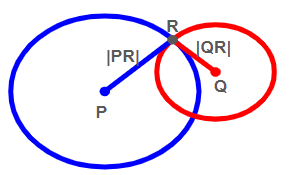


### Paso 1: Vector Base
$$\vec{PQ} = Q - P$$
$$d = |\vec{PQ}|$$

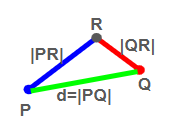


### Paso 2: Punto de Proyección S
Proyectamos **R** sobre la línea de **PQ**:
$$|PS| = \frac{|PR|^2 + |PQ|^2 - |QR|^2}{2|PQ|}$$
$$S = P + \frac{|PS|}{|PQ|} \vec{PQ}$$


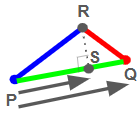




### Paso 3: Vector Perpendicular
Calculamos la distancia perpendicular $|SR|$ usando Pitágoras:
$$|SR| = \sqrt{|PR|^2 - |PS|^2}$$

Multiplicamos el vector unitario normal a $\vec{PQ}$ por la distancia $|SR|$ para obtener $\vec{v}$. Las dos soluciones posibles son:
$$R = S \pm \vec{v}$$

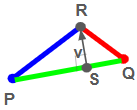

In [3]:
# @title
import math




def solve_third_point(P, Q, d_PR, d_QR):
    """
    Compute the possible coordinates of point R in a triangle.

    Given:
        P, Q : tuples (x, y) representing two known points
        d_PR : distance from P to R
        d_QR : distance from Q to R

    Returns:
        A tuple of two points (R1, R2), representing the two possible
        solutions (above and below line PQ).

    Method:
        - Project R onto line PQ → point S
        - Compute perpendicular distance |SR|
        - Move along perpendicular direction to get R
    """
    px, py = P
    qx, qy = Q

    # Vector PQ
    dx = qx - px
    dy = qy - py
    d = math.hypot(dx, dy)

    # Unit vector along PQ
    ux = dx / d
    uy = dy / d

    # Projection distance |PS|
    PS = (d_PR**2 + d**2 - d_QR**2) / (2 * d)

    # Point S
    sx = px + ux * PS
    sy = py + uy * PS

    # Perpendicular distance |SR|
    SR = math.sqrt(max(d_PR**2 - PS**2, 0))

    # Perpendicular unit vector
    perp_x = -uy
    perp_y = ux

    # Two possible R points
    R1 = Vec(sx + perp_x * SR, sy + perp_y * SR)
    R2 = Vec(sx - perp_x * SR, sy - perp_y * SR)

    return R1, R2

# Parte 2: Modelo del Robot Planar de Dos Barras (2R)

Un brazo robótico simple en el plano con dos articulaciones rotacionales e independientes medidos respecto a la horizontal.

* **l1**: Longitud del brazo primario.
* **l2**: Longitud del antebrazo.
* **q1**: Ángulo del primer eslabón con respecto a la horizontal.
* **q2**: Ángulo del segundo eslabón con respecto a la horizontal.

In [4]:
# @title
def update2(q1_deg,q2_deg):
    q1=q1_deg*pi/180
    q2=q2_deg*pi/180
    canvas=Axis(width=600,height=400, x_min = 0, y_min = 0, x_max = 600, y_max = 400,background_color="white")
    ab_length=300
    bc_length=200
    a_x=20
    a_y=20
    b_x=ab_length*cos(q1)
    b_y=ab_length*sin(q1)
    c_x=b_x+bc_length*cos(q2)
    c_y=b_y+bc_length*sin(q2)
    #print(int(a_x),int(a_y),int(b_x),int(b_y),int(c_x),int(c_y))

    a=Join_graph(canvas,(a_x,a_y),'a')
    b=Join_graph(canvas,(b_x,b_y),'b',move_text=(-8,-8))
    c=Join_graph(canvas,(c_x,c_y),'c')
    #d=Join_graph(canvas,(c_x,a_y),'d ')
    h=Join_graph(canvas,(c_x,b_y),'h')#,visible=False)
    v=Join_graph(canvas,(b_x,a_y),'v')#,visible=False)

    Link_graph(canvas,a,b,'l1')#,move_text=(0,-10))
    #Link_graph(canvas,a,c,'')
    Link_graph(canvas,a,v,'l1 cos(q1)='+str(int(b_x-a_x)))#,move_text=(0,15))
    #Link_graph(canvas,v,d,'')#,move_text=(0,15))
    Link_graph(canvas,b,c,'l2')
    Link_graph(canvas,b,h,'l2 cos(q2)='+str(int(c_x-b_x)))
    Link_graph(canvas,b,v,'l1 sin(q1)='+str(int(b_y-a_y)),move_text=(10,0))
    #Link_graph(canvas,d,h,'')#,move_text=(2,0))
    Link_graph(canvas,h,c,'l2 sin(q2)='+str(int(c_y-b_y)),move_text=(10,0))#,move_text=(2,0))

    #Angle_graph(canvas,c,a,b,"phi")
    Angle_graph(canvas,v,a,b,"q1",radius=60)
    Angle_graph(canvas,h,b,c,"q2",radius=20,label_d=(0,0))
    svg_code=canvas.get_svg()
    return SVG(svg_code)
#print(svg_code)
widgets.interact(update2, q1_deg=(10, 40, 1), q2_deg=(-10, 85, 1))

interactive(children=(IntSlider(value=25, description='q1_deg', max=40, min=10), IntSlider(value=37, descripti…

<function __main__.update2(q1_deg, q2_deg)>

## Cinemática Directa (2R)

Calcula la posición del efector final $(c_x, c_y)$ a partir de los ángulos articulares conocidos $q_1$ y $q_2$:

$$b_x = l_1 \cos(q_1)$$
$$b_y = l_1 \sin(q_1)$$
$$c_x = b_x + l_2 \cos(q_2)$$
$$c_y = b_y + l_2 \sin(q_2)$$

In [5]:
# @title
def update4(q1_deg,q2_deg):
    q1=q1_deg*pi/180
    q2=q2_deg*pi/180
    canvas=Axis(width=1000,height=400, x_min = 0, y_min = 0, x_max = 1000, y_max = 400,background_color="white")
    ab_length=300
    bc_length=200
    a_x=20
    a_y=20
    b_x=a_x+ab_length*cos(q1)
    b_y=a_y+ab_length*sin(q1)
    c_x=b_x+bc_length*cos(q2)
    c_y=b_y+bc_length*sin(q2)
    #print(int(a_x),int(a_y),int(b_x),int(b_y),int(c_x),int(c_y))

    a=Join_graph(canvas,(a_x,a_y),'a')
    b=Join_graph(canvas,(b_x,b_y),'b',move_text=(-8,-8))
    c=Join_graph(canvas,(c_x,c_y),'c')
    #d=Join_graph(canvas,(c_x,a_y),'d ')
    h=Join_graph(canvas,(c_x,b_y),'h')#,visible=False)
    v=Join_graph(canvas,(b_x,a_y),'v')#,visible=False)

    Link_graph(canvas,a,b,'l1')#,move_text=(0,-10))
    #Link_graph(canvas,a,c,'')
    Link_graph(canvas,a,v,'l1 cos(q1)='+str(int(b_x-a_x)))#,move_text=(0,15))
    #Link_graph(canvas,v,d,'')#,move_text=(0,15))
    Link_graph(canvas,b,c,'l2')
    Link_graph(canvas,b,h,'l2 cos(q2)='+str(int(c_x-b_x)))
    Link_graph(canvas,b,v,'l1 sin(q1)='+str(int(b_y-a_y)),move_text=(10,0))
    #Link_graph(canvas,d,h,'')#,move_text=(2,0))
    Link_graph(canvas,h,c,'l2 sin(q2)='+str(int(c_y-b_y)),move_text=(10,0))#,move_text=(2,0))

    #Angle_graph(canvas,c,a,b,"phi")
    Angle_graph(canvas,v,a,b,"q1",radius=60)
    Angle_graph(canvas,h,b,c,"q2",radius=20,label_d=(0,0))

    ac_length=sqrt((c_x-a_x)**2+(c_y-a_y)**2)
    phi1=law_cos(bc_length,ab_length,ac_length)
    phi2=atan2(c_y-a_y,c_x-a_x)

    #print('phi='+str(int(phi1))+'phi='+str(int(phi1)))

    qq1=phi2-phi1
    #print('c_x-ab_length*cos(qq1) / bc_length',c_x,a_x,ab_length*cos(qq1) , bc_length,c_x-a_x-ab_length*cos(qq1) / bc_length)
    qq2=acos((c_x-a_x-ab_length*cos(qq1)) / bc_length)

    a1_x=520
    a1_y=20
    b1_x=a1_x+ab_length*cos(qq1)
    b1_y=a1_y+ab_length*sin(qq1)
    c1_x=b1_x+bc_length*cos(qq2)
    c1_y=b1_y+bc_length*sin(qq2)
    #print(int(a_x),int(a_y),int(b_x),int(b_y),int(c_x),int(c_y))

    a1=Join_graph(canvas,(a1_x,a1_y),'a')
    b1=Join_graph(canvas,(b1_x,b1_y),'b',move_text=(-8,-8))
    c1=Join_graph(canvas,(c1_x,c1_y),'c')
    d1=Join_graph(canvas,(c1_x,a1_y),'d ')
    h1=Join_graph(canvas,(c1_x,b1_y),'h')#,visible=False)
    v1=Join_graph(canvas,(b1_x,a1_y),'v')#,visible=False)

    Link_graph(canvas,a1,b1,'l1')#,move_text=(0,-10))
    Link_graph(canvas,a1,c1,'ac')
    Link_graph(canvas,a1,v1,'')#l1 cos(q1)='+str(int(b1_x-a1_x)))#,move_text=(0,15))
    Link_graph(canvas,v1,d1,'')#,move_text=(0,15))
    Link_graph(canvas,b1,c1,'l2')
    Link_graph(canvas,b1,h1,'')#l2 cos(q2)='+str(int(c1_x-b1_x)))
    Link_graph(canvas,b1,v1,'')#l1 sin(q1)='+str(int(b1_y-a1_y)),move_text=(10,0))
    Link_graph(canvas,d1,h1,'')#,move_text=(2,0))
    Link_graph(canvas,h1,c1,'')#l2 sin(q2)='+str(int(c1_y-b1_y)),move_text=(10,0))#,move_text=(2,0))

    Angle_graph(canvas,c1,a1,b1,"phi1="+r2d_str(phi1))
    Angle_graph(canvas,c1,a1,d1,"phi2="+r2d_str(phi2),radius=80)
    Angle_graph(canvas,v1,a1,b1,"qq1",radius=60)
    Angle_graph(canvas,h1,b1,c1,"qq2",radius=20,label_d=(0,0))






    svg_code=canvas.get_svg()
    return SVG(svg_code)
#print(svg_code)
widgets.interact(update4, q1_deg=(10, 40, 1), q2_deg=(-10, 85, 1))

interactive(children=(IntSlider(value=25, description='q1_deg', max=40, min=10), IntSlider(value=37, descripti…

<function __main__.update4(q1_deg, q2_deg)>

## Cinemática Inversa (2R)

Determina los ángulos necesarios $q_1$ y $q_2$ para alcanzar una coordenada cartesiana objetivo $(c_x, c_y)$ usando la Ley de Cosenos aprendida en la Parte 1.

## Cinemática Inversa del MeArm

Aplicación combinada de trigonometría y relaciones de lazo cerrado para posicionar el extremo final en el espacio de trabajo deseado.

In [6]:
# @title
def update10(q1_deg,q2_deg):
    #q1=q1_deg*pi/180
    #q2=q2_deg*pi/180
    canvas=Axis(width=500,height=500, x_min = -1, y_min = -1, x_max = 2, y_max = 2,background_color="white",x_axis=True,y_axis=True)



    ctes= { "beta0_deg": 165, "beta1_deg": 90, "beta2_deg": 105 }
    li= {
            "A": 0.4 ,# { "nodes": ["a", "b"], "l": 0.4 },
            "B": 0.8 ,# { "nodes": ["a", "d"], "l": 0.8 },
            "C": 0.4 ,# { "nodes": ["d", "c"], "l": 0.4 },
            "D": 0.8 ,# { "nodes": ["c", "b"], "l": 0.8 },
            "E": 0.35,# { "nodes": ["d", "f"], "l": 0.35 },
            "F": 0.8 ,# { "nodes": ["f", "e"], "l": 0.8 },
            "G": 0.35,# { "nodes": ["a", "e"], "l": 0.35 },
            "H": 0.45,# { "nodes": ["c", "g"], "l": 0.45 },
            "I": 0.2 ,# { "nodes": ["d", "g"], "l": 0.2 },
            "J": 0.8 ,# { "nodes": ["d", "i"], "l": 0.8 },
            "K": 0.2 ,# { "nodes": ["i", "h"], "l": 0.2 },
            "L": 0.8 ,# { "nodes": ["g", "h"], "l": 0.8 },
            "M": 0.25,# { "nodes": ["i", "j"], "l": 0.25 }
        }

    a=Vec(0,0)
    b=Vec(li['A'],0).rot_deg(ctes['beta0_deg'])+ a
    d=Vec(li['B'],0).rot_deg(q1_deg)+ a
    c,cp=solve_third_point(b,d,li['D'],li['C'])#P, Q, d_PR, d_QR):
    #print(a,b,c,d)
    e=Vec(li['G'],0).rot_deg(q2_deg)+ a
    fp,f=solve_third_point(d,e,li['E'],li['F'])
    g=Vec(li['I'],0).rot(c.angle_line(d)+d2r(ctes['beta1_deg']))+ d
    i=Vec(li['J'],0).rot(f.angle_line(d))+ d
    h,hp=solve_third_point(g,i,li['L'],li['K'])
    j=Vec(li['M'],0).rot(h.angle_line(i)+d2r(ctes['beta2_deg']))+ i

    l_a=Join_graph(canvas,a,'a')
    l_b=Join_graph(canvas,b,'b')
    l_c=Join_graph(canvas,c,'c')
    l_d=Join_graph(canvas,d,'d')
    l_e=Join_graph(canvas,e,'e')
    l_f=Join_graph(canvas,f,'f')
    l_g=Join_graph(canvas,g,'g')
    l_h=Join_graph(canvas,h,'h')
    l_i=Join_graph(canvas,i,'i')
    l_j=Join_graph(canvas,j,'j')

    Link_graph(canvas,l_a,l_b,'')
    Link_graph(canvas,l_a,l_d,'')
    Link_graph(canvas,l_d,l_c,'')
    Link_graph(canvas,l_c,l_b,'')
    Link_graph(canvas,l_d,l_f,'')
    Link_graph(canvas,l_f,l_e,'')
    Link_graph(canvas,l_a,l_e,'')
    Link_graph(canvas,l_c,l_g,'')
    Link_graph(canvas,l_d,l_g,'')
    Link_graph(canvas,l_d,l_i,'')
    Link_graph(canvas,l_i,l_h,'')
    Link_graph(canvas,l_g,l_h,'')
    Link_graph(canvas,l_i,l_j,'')

    svg_code=canvas.get_svg()
    return SVG(svg_code)
#print(svg_code)
widgets.interact(update10, q1_deg=widgets.IntSlider(value=90, min=-180, max=180, step=5), q2_deg=widgets.IntSlider(value=-180, min=-180, max=180, step=5))

interactive(children=(IntSlider(value=90, description='q1_deg', max=180, min=-180, step=5), IntSlider(value=-1…

<function __main__.update10(q1_deg, q2_deg)>

# Parte 3: Brazo Robótico MeArm

El MeArm es un robot articulado que utiliza paralelogramos y estructuras de lazo cerrado para mantener el efector final orientado de manera estable.

## Cinemática Directa del MeArm
Calculamos secuencialmente las posiciones de todos los pivotes mecánicos utilizando la función `solve_third_point` desarrollada en la Parte 1.

In [7]:
# @title
def update11(q1_deg,q2_deg):
    #q1=q1_deg*pi/180
    #q2=q2_deg*pi/180
    canvas=Axis(width=1000,height=500, x_min = -1, y_min = -1, x_max = 5, y_max = 2,background_color="white",x_axis=True,y_axis=True)



    ctes= { "beta0_deg": 180, "beta1_deg": 90, "beta2_deg": 105 }
    li= {
            "A": 0.4 ,# { "nodes": ["a", "b"], "l": 0.4 },
            "B": 0.8 ,# { "nodes": ["a", "d"], "l": 0.8 },
            "C": 0.4 ,# { "nodes": ["d", "c"], "l": 0.4 },
            "D": 0.8 ,# { "nodes": ["c", "b"], "l": 0.8 },
            "E": 0.35,# { "nodes": ["d", "f"], "l": 0.35 },
            "F": 0.8 ,# { "nodes": ["f", "e"], "l": 0.8 },
            "G": 0.35,# { "nodes": ["a", "e"], "l": 0.35 },
            "H": 0.45,# { "nodes": ["c", "g"], "l": 0.45 },
            "I": 0.2 ,# { "nodes": ["d", "g"], "l": 0.2 },
            "J": 0.8 ,# { "nodes": ["d", "i"], "l": 0.8 },
            "K": 0.2 ,# { "nodes": ["i", "h"], "l": 0.2 },
            "L": 0.8 ,# { "nodes": ["g", "h"], "l": 0.8 },
            "M": 0.25,# { "nodes": ["i", "j"], "l": 0.25 }
        }

    a=Vec(0,0)
    b=Vec(li['A'],0).rot_deg(ctes['beta0_deg'])+ a
    d=Vec(li['B'],0).rot_deg(q1_deg)+ a
    c,cp=solve_third_point(b,d,li['D'],li['C'])#P, Q, d_PR, d_QR):
    #print(a,b,c,d)
    e=Vec(li['G'],0).rot_deg(q2_deg)+ a
    fp,f=solve_third_point(d,e,li['E'],li['F'])
    g=Vec(li['I'],0).rot(c.angle_line(d)+d2r(ctes['beta1_deg']))+ d
    i=Vec(li['J'],0).rot(f.angle_line(d))+ d
    h,hp=solve_third_point(g,i,li['L'],li['K'])
    j=Vec(li['M'],0).rot(h.angle_line(i)+d2r(ctes['beta2_deg']))+ i

    l_a=Join_graph(canvas,a,'a')
    l_b=Join_graph(canvas,b,'b')
    l_c=Join_graph(canvas,c,'c')
    l_d=Join_graph(canvas,d,'d')
    l_e=Join_graph(canvas,e,'e')
    l_f=Join_graph(canvas,f,'f')
    l_g=Join_graph(canvas,g,'g')
    l_h=Join_graph(canvas,h,'h')
    l_i=Join_graph(canvas,i,'i')
    l_j=Join_graph(canvas,j,'j')

    Link_graph(canvas,l_a,l_b,'')
    Link_graph(canvas,l_a,l_d,'')
    Link_graph(canvas,l_d,l_c,'')
    Link_graph(canvas,l_c,l_b,'')
    Link_graph(canvas,l_d,l_f,'')
    Link_graph(canvas,l_f,l_e,'')
    Link_graph(canvas,l_a,l_e,'')
    Link_graph(canvas,l_c,l_g,'')
    Link_graph(canvas,l_d,l_g,'')
    Link_graph(canvas,l_d,l_i,'')
    Link_graph(canvas,l_i,l_h,'')
    Link_graph(canvas,l_g,l_h,'')
    Link_graph(canvas,l_i,l_j,'')

    ad_length=(a-d).norm()
    ai_length=(a-i).norm()
    di_length=(d-i).norm()

    phi1=law_cos(di_length,ad_length,ai_length)
    print('phi1='+r2d_str(phi1))
    phi2=a.angle_line(i)#atan2(i_y-a_y,i_x-a_x)
    print('phi2='+r2d_str(phi2))

    #print('phi='+str(int(phi1))+'phi='+str(int(phi1)))

    qq1=phi2+phi1
    print('qq1='+r2d_str(qq1))
    #print('c_x-ab_length*cos(qq1) / bc_length',c_x,a_x,ab_length*cos(qq1) , bc_length,c_x-a_x-ab_length*cos(qq1) / bc_length)
    print('(i[0]-a[0]-ad_length*cos(qq1)) / di_length',i[0],a[0],ad_length,cos(qq1),i[0]-a[0]-ad_length*cos(qq1) , di_length)
    #qq2=#acos((i[0]-a[0]-(ad_length*cos(qq1))) / di_length)+pi



    a1=Vec(3,0)
    b1=Vec(li['A'],0).rot_deg(ctes['beta0_deg'])+ a1
    d1=Vec(li['B'],0).rot(qq1)+ a1
    qq2=d1.angle_line(i-a+a1)+pi
    print('qq2='+r2d_str(qq2),d1,i)
    c1,cp1=solve_third_point(b1,d1,li['D'],li['C'])#P, Q, d_PR, d_QR):
    #print(a,b,c,d)
    e1=Vec(li['G'],0).rot(qq2)+ a1
    fp1,f1=solve_third_point(d1,e1,li['E'],li['F'])
    g1=Vec(li['I'],0).rot(c1.angle_line(d1)+d2r(ctes['beta1_deg']))+ d1
    i1=Vec(li['J'],0).rot(f1.angle_line(d1))+ d1
    h1,hp1=solve_third_point(g1,i1,li['L'],li['K'])
    j1=Vec(li['M'],0).rot(h1.angle_line(i1)+d2r(ctes['beta2_deg']))+ i1

    l_a1=Join_graph(canvas,a1,'a')
    l_b1=Join_graph(canvas,b1,'b')
    l_c1=Join_graph(canvas,c1,'c')
    l_d1=Join_graph(canvas,d1,'d')
    l_e1=Join_graph(canvas,e1,'e')
    l_f1=Join_graph(canvas,f1,'f')
    l_g1=Join_graph(canvas,g1,'g')
    l_h1=Join_graph(canvas,h1,'h')
    l_i1=Join_graph(canvas,i1,'i')
    l_j1=Join_graph(canvas,j1,'j')

    Link_graph(canvas,l_a1,l_b1,'')
    Link_graph(canvas,l_a1,l_d1,'')
    Link_graph(canvas,l_d1,l_c1,'')
    Link_graph(canvas,l_c1,l_b1,'')
    Link_graph(canvas,l_d1,l_f1,'')
    Link_graph(canvas,l_f1,l_e1,'')
    Link_graph(canvas,l_a1,l_e1,'')
    Link_graph(canvas,l_c1,l_g1,'')
    Link_graph(canvas,l_d1,l_g1,'')
    Link_graph(canvas,l_d1,l_i1,'')
    Link_graph(canvas,l_i1,l_h1,'')
    Link_graph(canvas,l_g1,l_h1,'')
    Link_graph(canvas,l_i1,l_j1,'')







    svg_code=canvas.get_svg()
    return SVG(svg_code)
#print(svg_code)
widgets.interact(update11, q1_deg=widgets.IntSlider(value=90, min=-180, max=180, step=5), q2_deg=widgets.IntSlider(value=-180, min=-180, max=180, step=5))



    # ac_length=sqrt((c_x-a_x)**2+(c_y-a_y)**2)
    # phi1=law_cos(bc_length,ab_length,ac_length)
    # phi2=atan2(c_y-a_y,c_x-a_x)

    # #print('phi='+str(int(phi1))+'phi='+str(int(phi1)))

    # qq1=phi2-phi1
    # #print('c_x-ab_length*cos(qq1) / bc_length',c_x,a_x,ab_length*cos(qq1) , bc_length,c_x-a_x-ab_length*cos(qq1) / bc_length)
    # qq2=acos((c_x-a_x-ab_length*cos(qq1)) / bc_length)



interactive(children=(IntSlider(value=90, description='q1_deg', max=180, min=-180, step=5), IntSlider(value=-1…

<function __main__.update11(q1_deg, q2_deg)>

In [8]:
# @title


In [9]:
# @title
